WINE QUALITY PREDICTION BY MOHAMMED INABAH KHAN

1. INSTALLING DEPENDENCIES

In [ ]:
%pip install -q "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

2. IMPORTS AND LOADING THE DATASET FROM KAGGLE

In [27]:
import kagglehub
import pandas as pd
from kagglehub import KaggleDatasetAdapter

DATASET = "uciml/red-wine-quality-cortez-et-al-2009"
file_path = "winequality-red.csv"

# Reload the CSV with the correct separator
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    file_path,
    pandas_kwargs={"sep": ";", "header": 0}
)

df.columns = df.columns.str.strip()

print(df.columns.tolist())

# Your current DataFrame has all values in one column.
# Split each row using commas.
df = df.iloc[:, 0].str.split(",", expand=True)

# Set the correct column names
df.columns = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "quality"
]

# Convert all values to numeric
df = df.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

/tmp/ipykernel_2771/2187249436.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.
['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality']
Dataset shape: (1599, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


3. INITAL INSPECTION AND DATA QUALITY

In [28]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nQuality score counts:")
display(df["quality"].value_counts().sort_index())

Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

D

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



Quality score counts:


,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


4. EXPLORATORY DATA ANALYSIS

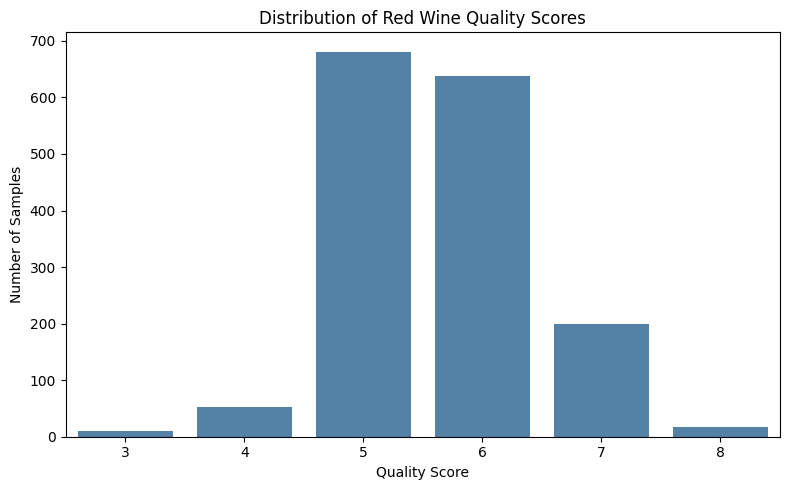

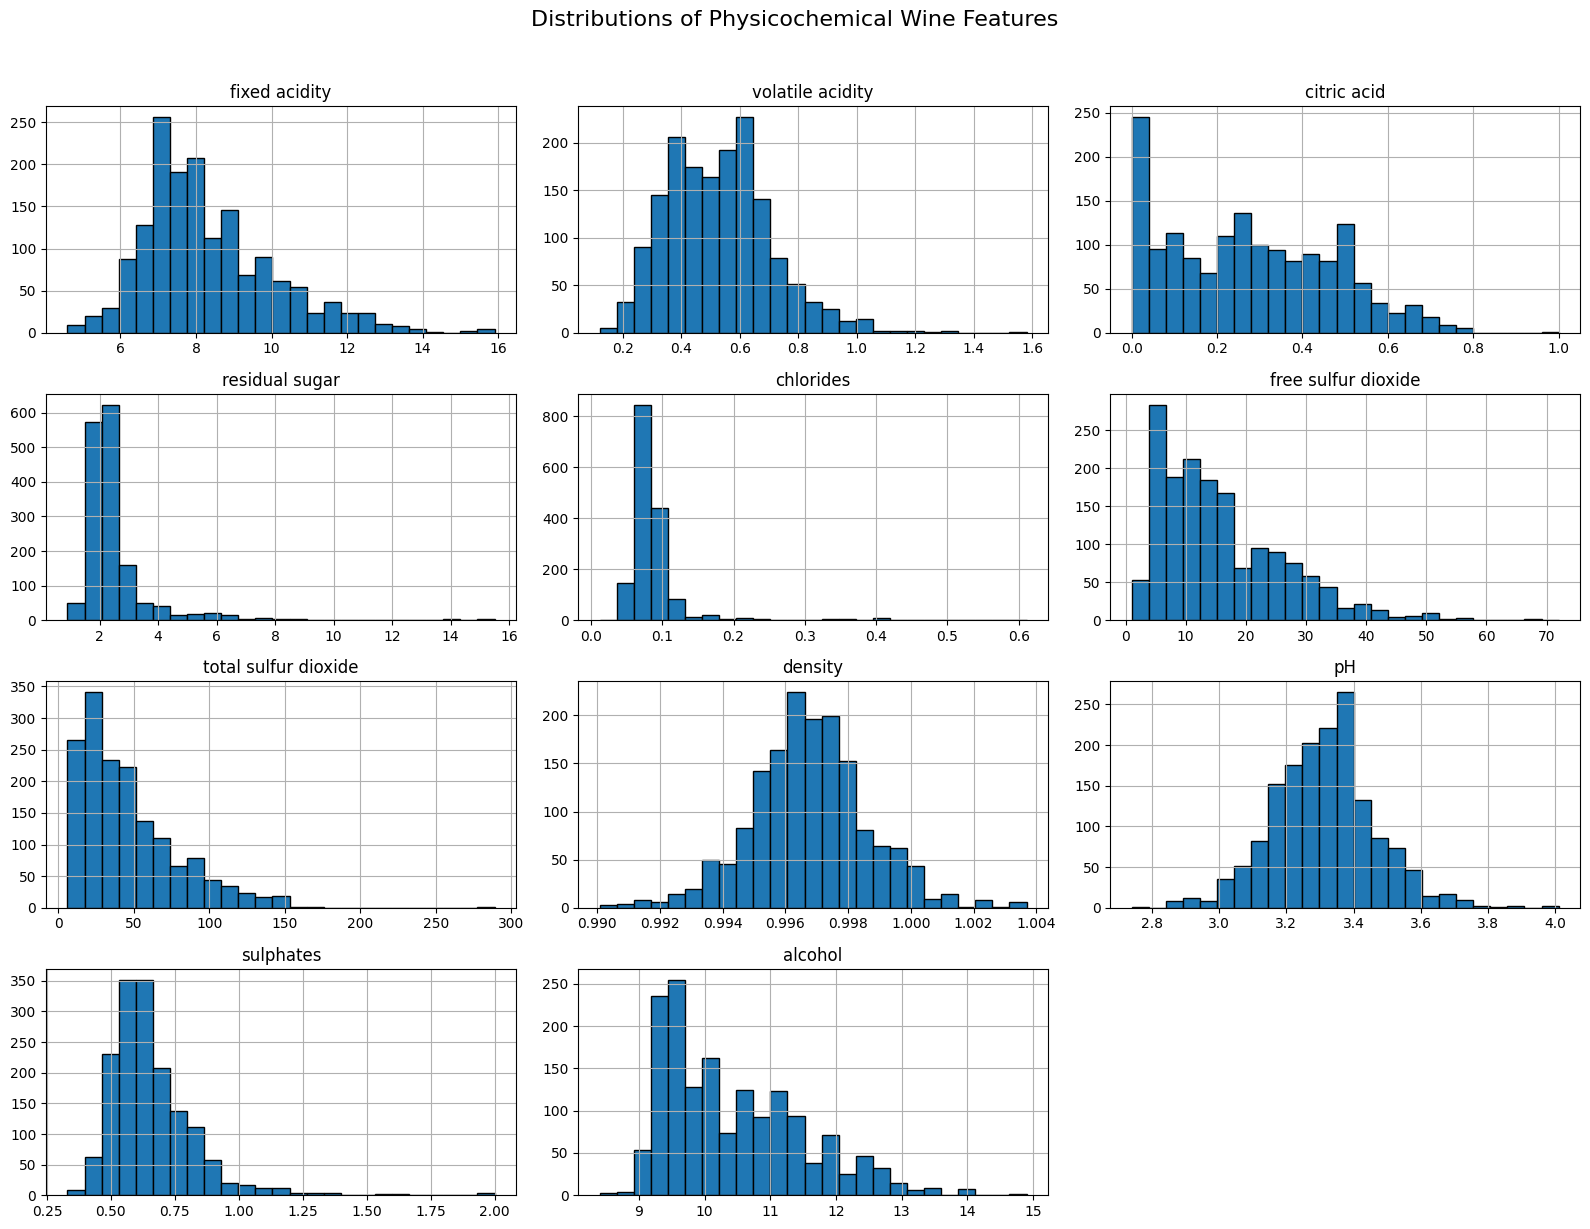

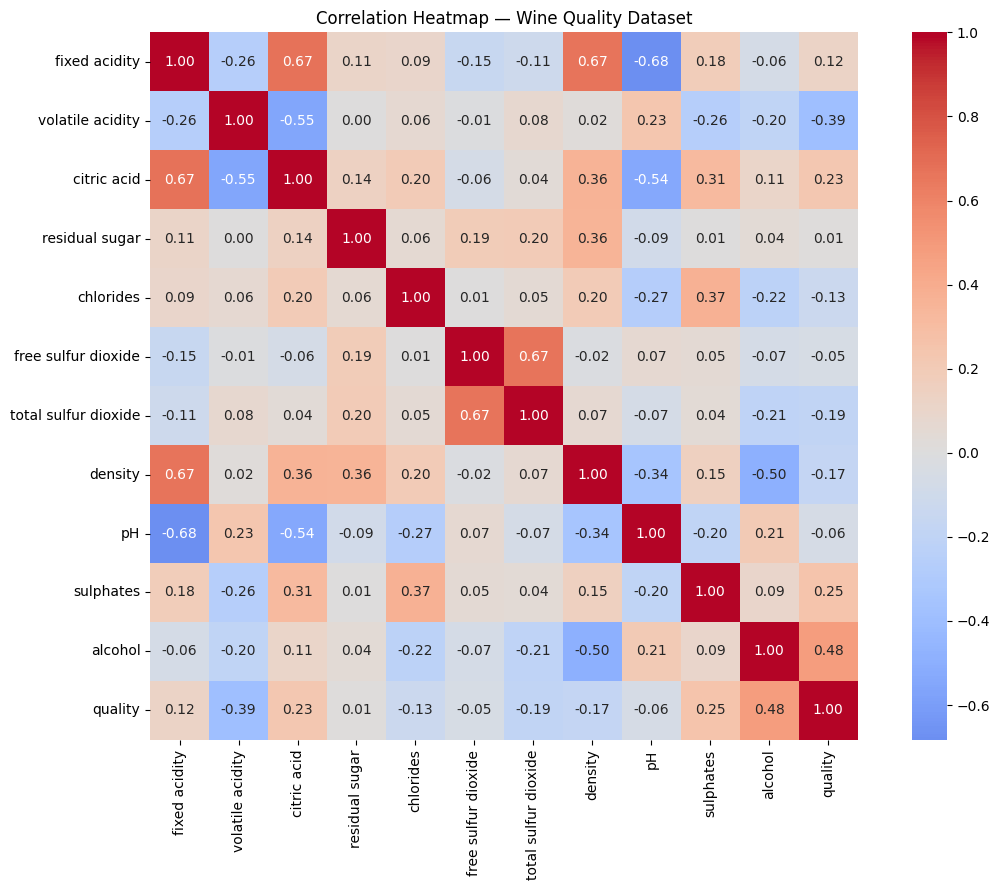

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="quality",
    color="steelblue"
)

plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

features = df.drop(columns="quality").columns

df[features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Physicochemical Wine Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Heatmap — Wine Quality Dataset")
plt.tight_layout()
plt.show()



5. ANALYSE CLASS IMBALANCE

,Count,Percentage
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


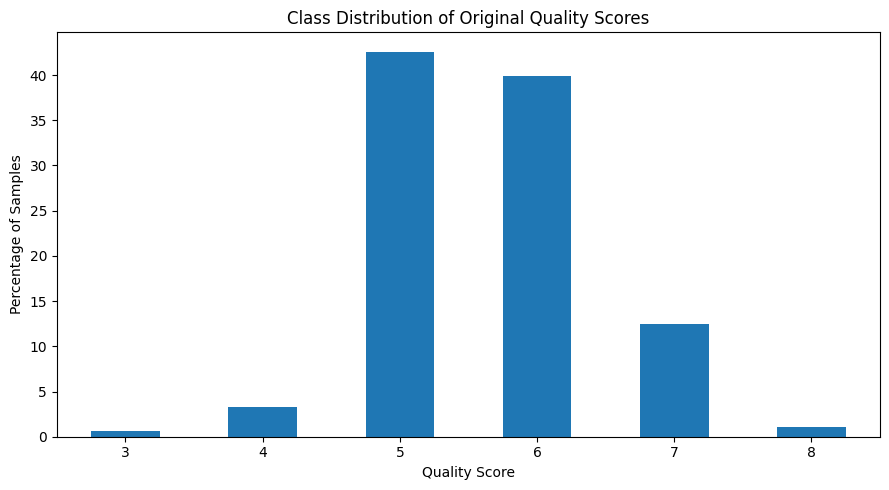

In [30]:
quality_counts = df["quality"].value_counts().sort_index()

quality_summary = pd.DataFrame({
    "Count": quality_counts,
    "Percentage": (
        quality_counts / len(df) * 100
    ).round(2)
})

display(quality_summary)

plt.figure(figsize=(9, 5))
quality_summary["Percentage"].plot(kind="bar")

plt.title("Class Distribution of Original Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Percentage of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

6. FEATURE ENGINEERING

In [31]:
def group_quality(score):
    if score <= 5:
        return "Low"
    elif score == 6:
        return "Medium"
    else:
        return "High"

df["quality_class"] = df["quality"].apply(group_quality)

class_order = ["Low", "Medium", "High"]

print("Three-class distribution:")
display(
    df["quality_class"]
    .value_counts()
    .reindex(class_order)
    .rename("Count")
    .to_frame()
)

print("\nThree-class percentages:")
display(
    (
        df["quality_class"].value_counts(normalize=True)
        .reindex(class_order) * 100
    ).round(2).rename("Percentage").to_frame()
)

Three-class distribution:


,Count
quality_class,
Low,744
Medium,638
High,217



Three-class percentages:


,Percentage
quality_class,
Low,46.53
Medium,39.90
High,13.57


7. PREPARE FEATURES AND SPLIT THE DATA

In [32]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality", "quality_class"])
y = df["quality_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).reindex(class_order).round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).reindex(class_order).round(3))

Training samples: 1279
Testing samples: 320

Training class proportions:


,proportion
quality_class,
Low,0.465
Medium,0.399
High,0.136



Testing class proportions:


,proportion
quality_class,
Low,0.466
Medium,0.400
High,0.134


8. TRAINING ALL THREE CLASSIFIERS

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

models = {
    "Random Forest": Pipeline([
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]),

    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            loss="hinge",
            max_iter=3000,
            tol=1e-3,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ])
}

fitted_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    fitted_models[name] = model
    predictions[name] = model.predict(X_test)

    print(f"{name} training complete.")

print("\nAll three classifiers have been trained.")

Training Random Forest...
Random Forest training complete.
Training SGD Classifier...
SGD Classifier training complete.
Training SVC...
SVC training complete.

All three classifiers have been trained.


9. EVALUATING THE THREE MODELS


Classification Report — Random Forest
              precision    recall  f1-score   support

         Low       0.81      0.83      0.82       149
      Medium       0.70      0.72      0.71       128
        High       0.69      0.56      0.62        43

    accuracy                           0.75       320
   macro avg       0.73      0.70      0.71       320
weighted avg       0.75      0.75      0.75       320



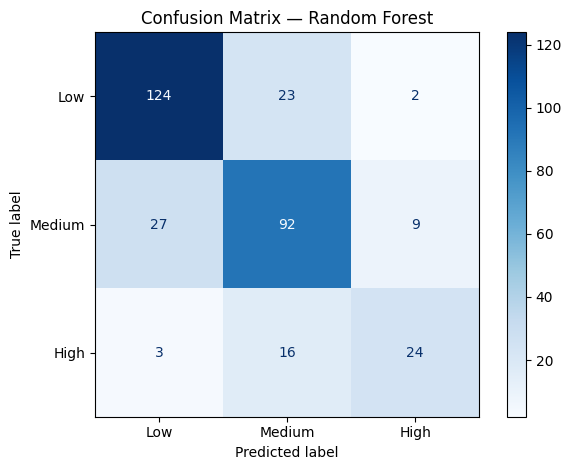


Classification Report — SGD Classifier
              precision    recall  f1-score   support

         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128
        High       0.23      0.33      0.27        43

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320



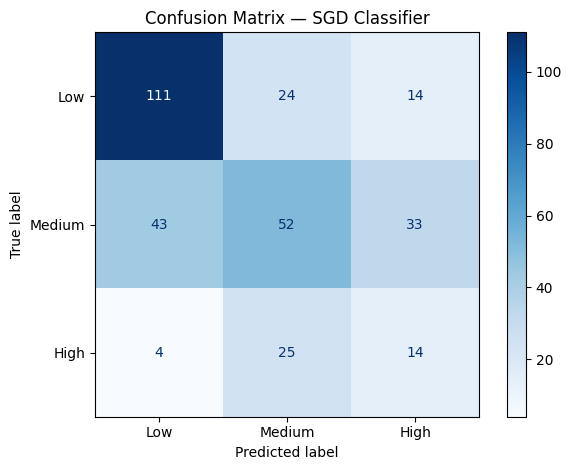


Classification Report — SVC
              precision    recall  f1-score   support

         Low       0.73      0.77      0.75       149
      Medium       0.57      0.40      0.47       128
        High       0.41      0.70      0.51        43

    accuracy                           0.61       320
   macro avg       0.57      0.62      0.58       320
weighted avg       0.62      0.61      0.60       320



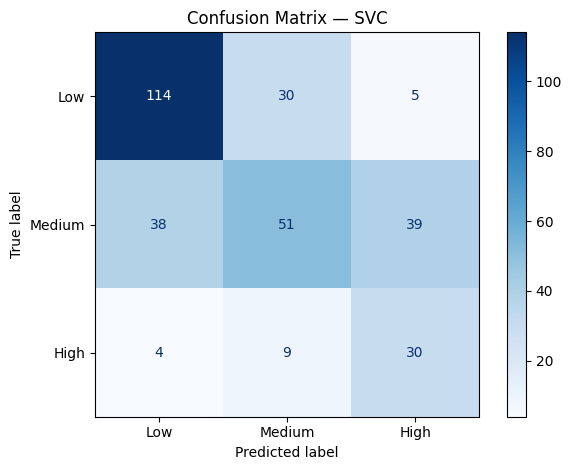


Final comparison table:


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Random Forest,0.7500,0.7311,0.7030,0.7148,0.7480
SGD Classifier,0.5531,0.4823,0.4923,0.4822,0.5545
SVC,0.6094,0.5676,0.6204,0.5761,0.6041


In [34]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, y_pred in predictions.items():
    print("\n" + "=" * 60)
    print(f"Classification Report — {name}")
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=class_order,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_order
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_order
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

print("\nFinal comparison table:")
display(results_df.round(4))

10. FEATURE IMPORTANCE FOR RANDOM FOREST

,Feature,Importance
10,alcohol,0.166144
9,sulphates,0.116120
1,volatile acidity,0.110924
6,total sulfur dioxide,0.094993
2,citric acid,0.088965
7,density,0.082866
4,chlorides,0.076503
0,fixed acidity,0.070566
8,pH,0.067648
3,residual sugar,0.062798


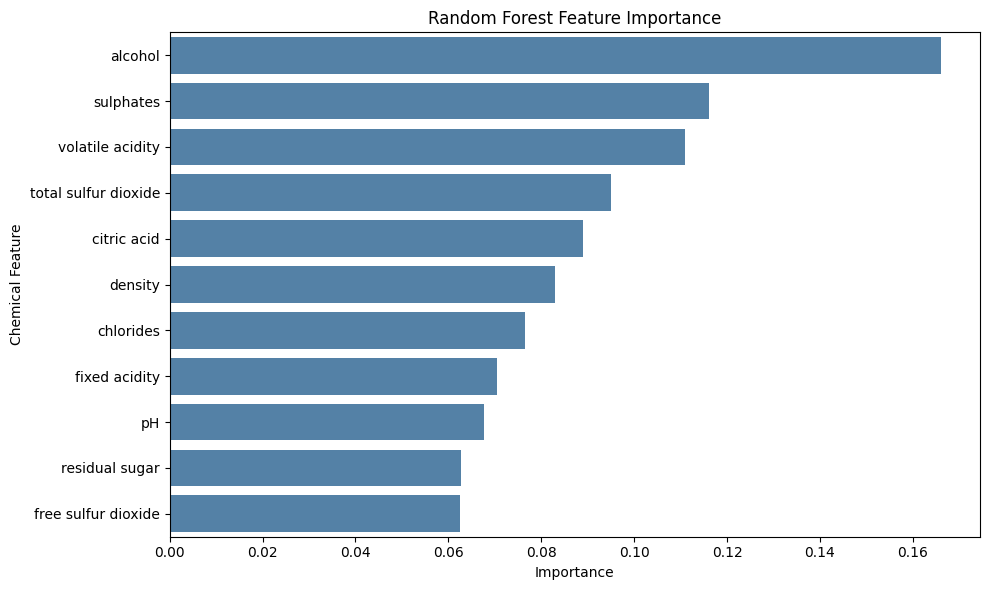

In [35]:
rf_model = fitted_models["Random Forest"]

rf_classifier = rf_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.show()

11. COMPARING THE MODELS SIDE-BY-SIDE

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Random Forest,0.7500,0.7311,0.7030,0.7148,0.7480
SVC,0.6094,0.5676,0.6204,0.5761,0.6041
SGD Classifier,0.5531,0.4823,0.4923,0.4822,0.5545


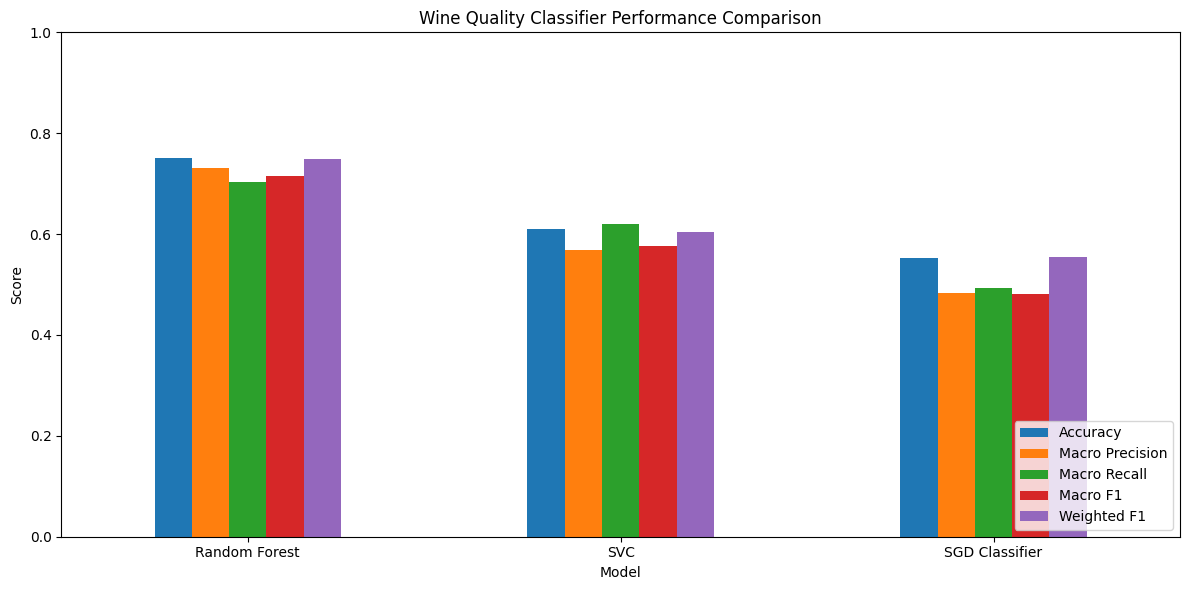

In [36]:
comparison = results_df[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]
].sort_values("Macro F1", ascending=False)

display(comparison.round(4))

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Wine Quality Classifier Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

11. SELECTING THE BEST MODEL

In [37]:
best_model_name = results_df["Macro F1"].idxmax()
best_model = fitted_models[best_model_name]

print("Model selected by Macro F1:", best_model_name)
print("\nSelected model's results:")
display(results_df.loc[[best_model_name]].round(4))

Model selected by Macro F1: Random Forest

Selected model's results:


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Random Forest,0.75,0.7311,0.703,0.7148,0.748


# Conclusion — Wine Quality Prediction

This project used the Red Wine Quality dataset obtained from Kaggle to investigate whether physicochemical measurements could be used to classify wine quality. The dataset included chemical features such as acidity, residual sugar, chlorides, density, sulphates, and alcohol content, together with a quality score.

Exploratory data analysis was performed using descriptive statistics, feature distribution plots, a quality-score distribution chart, and a correlation heatmap. The analysis also examined the imbalance in the original quality scores.

For classification, the original quality scores were grouped into three categories: Low (score ≤ 5), Medium (score = 6), and High (score ≥ 7). The dataset was divided into training and testing sets using an 80/20 stratified split. Random Forest, SGD Classifier, and Support Vector Classifier models were trained and evaluated.

The models were compared using accuracy, classification reports, confusion matrices, Macro F1, and Weighted F1. The Random Forest model's feature importances were also examined to identify which chemical measurements contributed most to its predictions.

**Model selection:** Model selected by Macro F1: Random Forest

Selected model's results:

Accuracy: 0.75,	Macro Precision: 0.7311,	Macro Recall:	0.703, Macro F1: 0.7148, Weighted F1: 0.748

Based on the evaluation, Random Forest was selected as the most promising candidate.

A potential application is preliminary quality screening, helping producers identify wines whose chemical profiles resemble those associated with lower or higher sensory quality scores. However, the model should support rather than replace sensory testing or expert evaluation.

The analysis has limitations. The quality classes depend on the selected thresholds, the original classes are imbalanced, and the model was evaluated on a single held-out split. Feature importance does not establish causation, and performance on this dataset does not guarantee generalization to wines from other producers or regions. Further validation, cross-validation, and hyperparameter tuning would be appropriate before deployment.